## **მონაცემთა ვიზუალიზაცია: Matplotlib, Seaborn, Plotly**

ოფიციალური დოკუმენტაცია:  [Matplotlib](https://matplotlib.org/stable/), [Seaborn](https://seaborn.pydata.org/), [Plotly](https://plotly.com/python/)


In [2]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import plotly.express as px

### Matplotlib

In [36]:
# სინთეზური მონაცემების გენერაცია
np.random.seed(42)
x1 = np.linspace(0, 10, 100) # x
y1 = 2 * x1 + np.random.normal(0, 3, 100) # y = 2x + noise
y2 = x1 * x1 + np.random.normal(0, 3, 100) # y = x² + noise

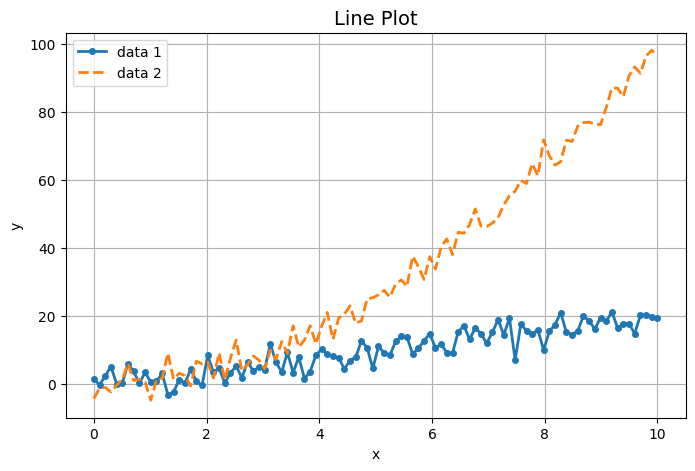

In [3]:
# Line Plot
plt.figure(figsize=(8, 5)) #  creates a new figure window
plt.plot(x1, y1, label="data 1", color="C0", marker="o", markersize=4, linewidth=2)
plt.plot(x1, y2, label="data 2", color="C1", linestyle="--", linewidth=2)

# Labels and Title
plt.title("Line Plot", fontsize=14)
plt.xlabel("x")
plt.ylabel("y")
plt.legend()
plt.grid(True)
plt.show()

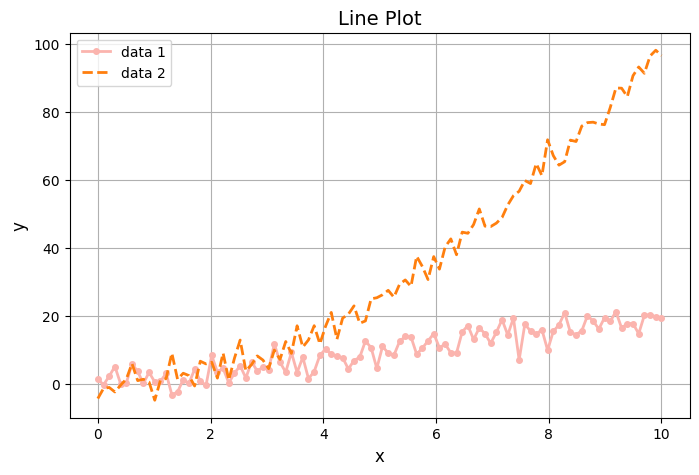

In [176]:
# Line Plot
fig, ax = plt.subplots(figsize=(8, 5))  # create a figure and a single Axes object

ax.plot(x1, y1, label="data 1", color=plt.cm.Pastel1(0), marker="o", markersize=4, linewidth=2) # colormap Pastel1
ax.plot(x1, y2, label="data 2", color="C1", linestyle="--", linewidth=2)

ax.set_title("Line Plot", fontsize=14)
ax.set_xlabel("x", fontsize=12)
ax.set_ylabel("y", fontsize=12)
ax.legend()
ax.grid(True)

plt.show()

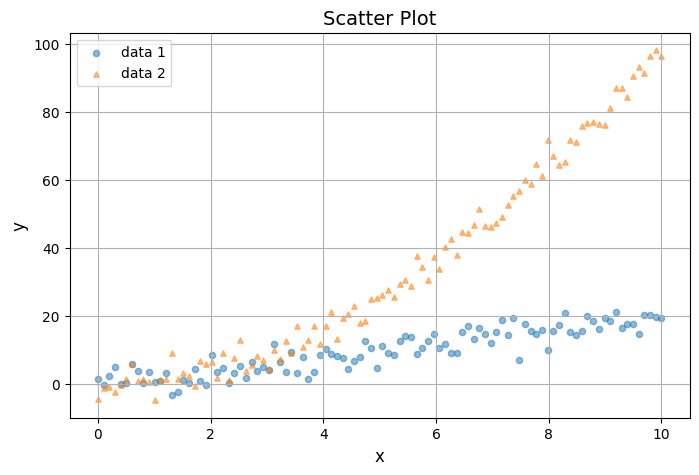

In [76]:
# Scatter Plot იგივე მონაცემებით
fig, ax = plt.subplots(figsize=(8, 5))

ax.scatter(x1, y1, label="data 1", color="C0", marker="o", s=20, alpha=0.5)
ax.scatter(x1, y2, label="data 2", color="C1", marker="^", s=15, alpha=0.5)

ax.set_title("Scatter Plot", fontsize=14)
ax.set_xlabel("x", fontsize=12)
ax.set_ylabel("y", fontsize=12)
ax.legend()
ax.grid(True)

plt.show()

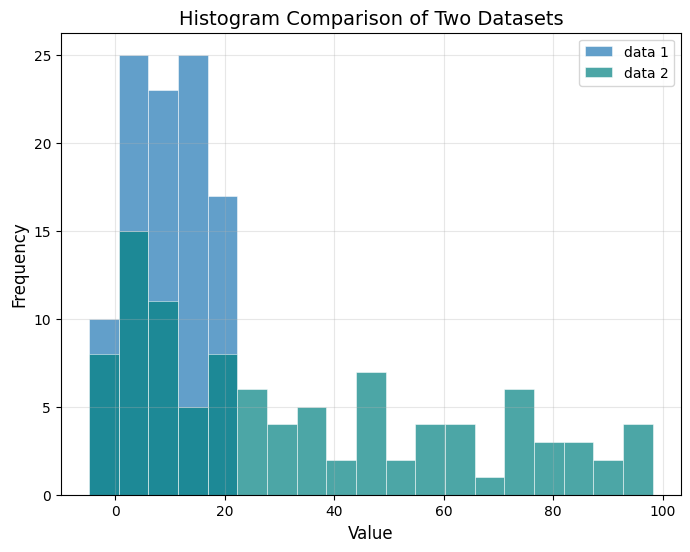

In [91]:
fig, ax = plt.subplots(figsize=(8, 6))

y_min = min(y1.min(), y2.min())
y_max = max(y1.max(), y2.max())
bins = np.linspace(y_min, y_max, 20)

ax.hist(y1, bins=bins, linewidth=0.5, edgecolor="white", alpha=0.7, label="data 1", color="C0")
ax.hist(y2, bins=bins, linewidth=0.5, edgecolor="white", alpha=0.7, label="data 2", color="teal")

ax.set_title("Histogram Comparison of Two Datasets", fontsize=14)
ax.set_xlabel("Value", fontsize=12)
ax.set_ylabel("Frequency", fontsize=12)
ax.legend()
ax.grid(alpha=0.3)

plt.show()

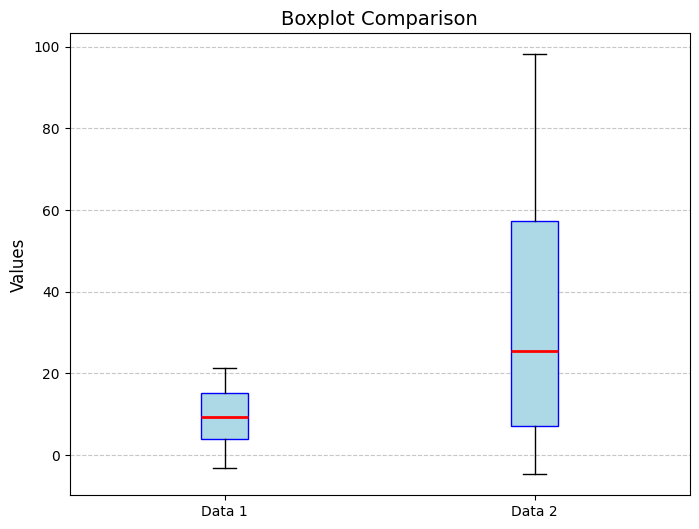

In [111]:
fig, ax = plt.subplots(figsize=(8, 6))

ax.boxplot([y1, y2], positions=[1, 2], patch_artist=True,
            boxprops=dict(facecolor="lightblue", color="blue"),
            medianprops=dict(color="red", linewidth=2))

# Labels & Title
ax.set_xticks([1, 2])
ax.set_xticklabels(["Data 1", "Data 2"])
ax.set_title("Boxplot Comparison", fontsize=14)
ax.set_ylabel("Values", fontsize=12)
ax.grid(True, axis="y", linestyle="--", alpha=0.7)

plt.show()

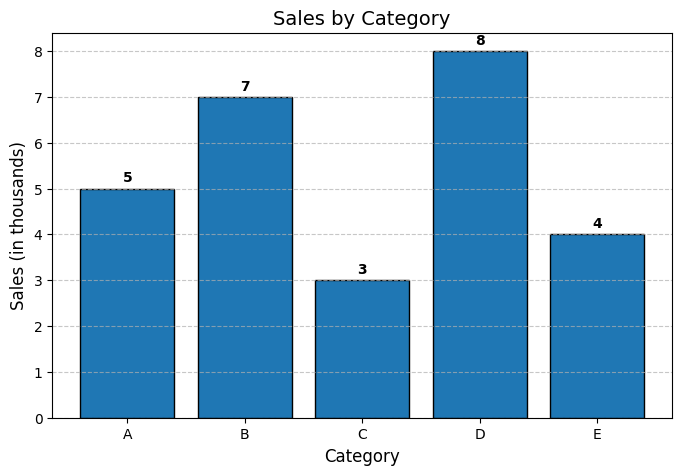

In [118]:
# კატეგორიები და მათი მნიშვნელობები
categories = ["A", "B", "C", "D", "E"]
values = [5, 7, 3, 8, 4]

# Bar plot
plt.figure(figsize=(8, 5))
plt.bar(categories, values, color="C0", edgecolor="black")

plt.title("Sales by Category", fontsize=14)
plt.xlabel("Category", fontsize=12)
plt.ylabel("Sales (in thousands)", fontsize=12)
plt.grid(axis="y", linestyle="--", alpha=0.7)

# add value labels above bars
for i, v in enumerate(values):
    plt.text(i, v + 0.15, str(v), ha="center", fontweight="bold")

plt.show()

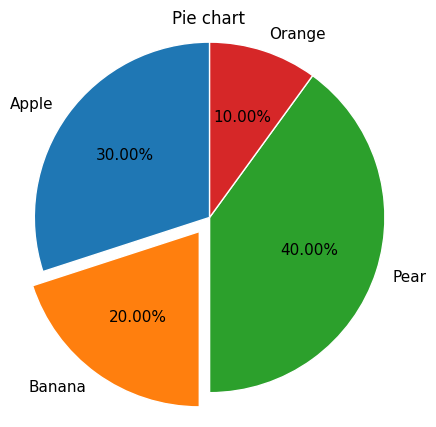

In [138]:
# კატეგორიები და მათი მნიშვნელობები
labels = ["Apple", "Banana", "Pear", "Orange"]
sizes = [30, 20, 40, 10]
explode = (0, 0.1, 0, 0) 

# pie chart
fig, ax = plt.subplots(figsize=(5, 5))
ax.pie(sizes, labels=labels, autopct="%.2f%%", startangle=90, explode=explode, textprops={"fontsize": 11}, wedgeprops={"edgecolor": "white"})
ax.set_title("Pie chart")
ax.axis("equal")
plt.show()

### Seaborn

#### Penguins Dataset

<img src="../../images/penguin.png" alt="penguin" width="700">

In [140]:
# Penguins Dataset
df = sns.load_dataset("penguins")
df = df.dropna()
df.head()

,species,island,bill_length_mm,bill_depth_mm,flipper_length_mm,body_mass_g,sex
0,Adelie,Torgersen,39.1,18.7,181.0,3750.0,Male
1,Adelie,Torgersen,39.5,17.4,186.0,3800.0,Female
2,Adelie,Torgersen,40.3,18.0,195.0,3250.0,Female
4,Adelie,Torgersen,36.7,19.3,193.0,3450.0,Female
5,Adelie,Torgersen,39.3,20.6,190.0,3650.0,Male


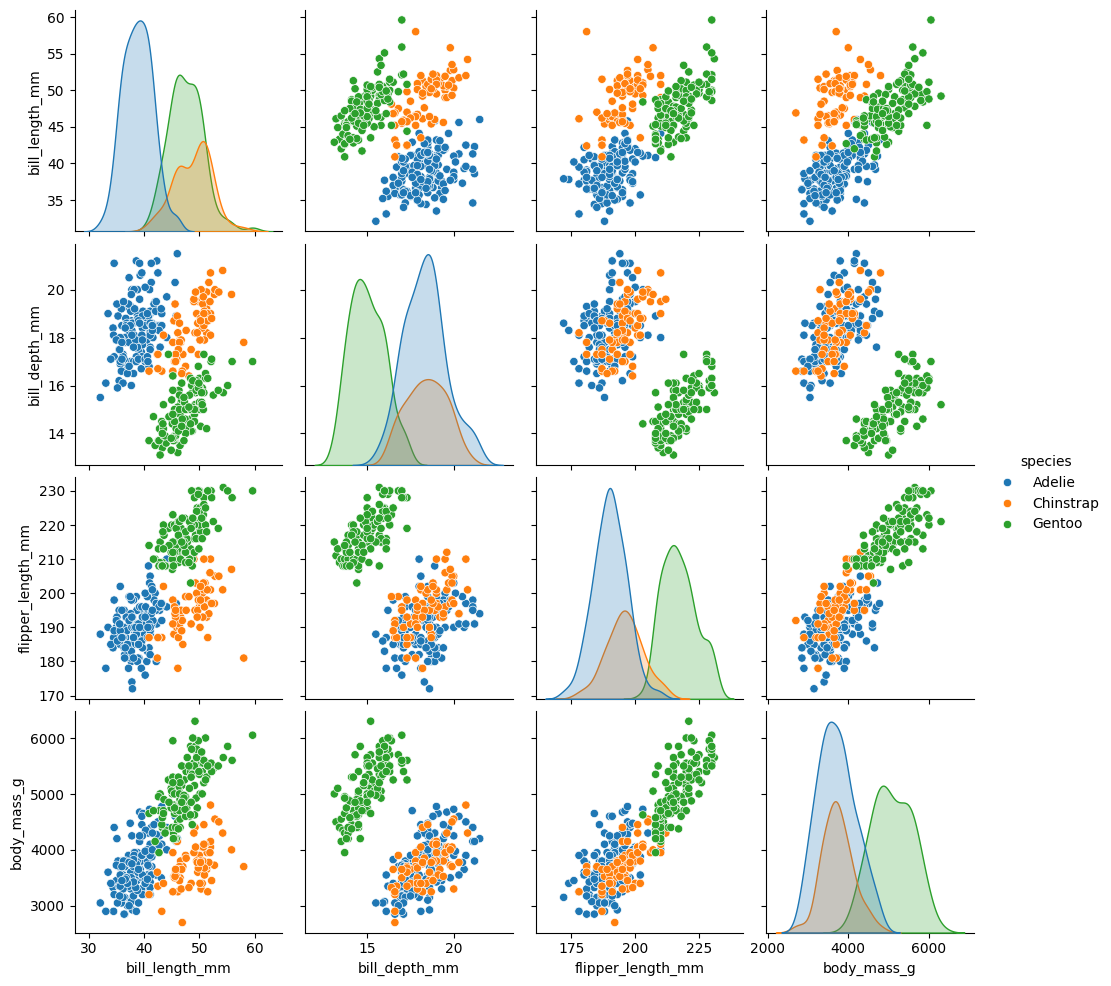

In [147]:
sns.pairplot(df, hue="species");

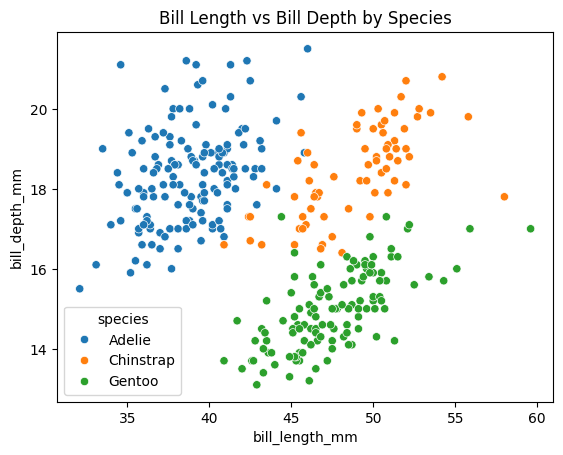

In [159]:
sns.scatterplot(data=df, x="bill_length_mm", y="bill_depth_mm", hue="species")
plt.title("Bill Length vs Bill Depth by Species")
plt.show()

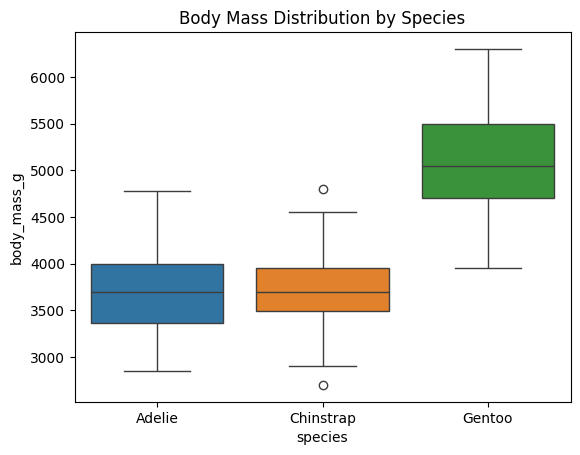

In [160]:
sns.boxplot(data=df, x="species", y="body_mass_g", hue="species")
plt.title("Body Mass Distribution by Species")
plt.show()

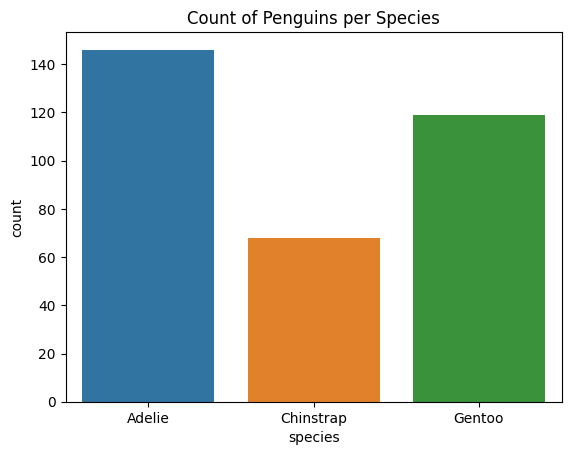

In [162]:
sns.countplot(data=df, x="species", hue="species")
plt.title("Count of Penguins per Species")
plt.show()

In [163]:
numeric_df = df.dropna().select_dtypes(include=np.number)
corr = numeric_df.corr()
corr

,bill_length_mm,bill_depth_mm,flipper_length_mm,body_mass_g
bill_length_mm,1.000000,-0.228626,0.653096,0.589451
bill_depth_mm,-0.228626,1.000000,-0.577792,-0.472016
flipper_length_mm,0.653096,-0.577792,1.000000,0.872979
body_mass_g,0.589451,-0.472016,0.872979,1.000000


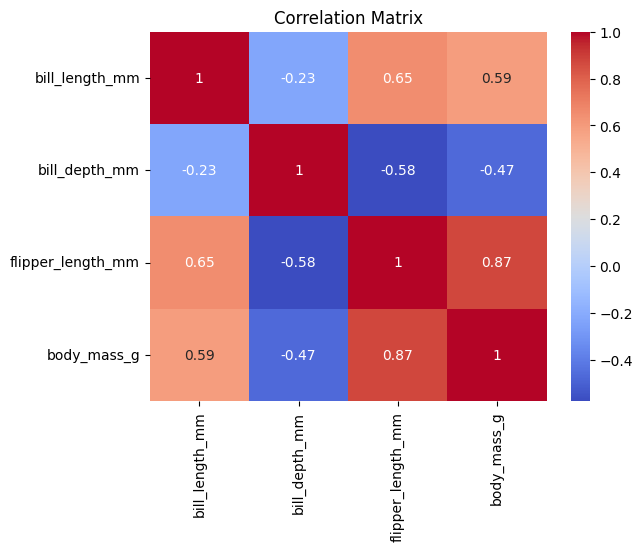

In [167]:
numeric_df = df.dropna().select_dtypes(include=np.number)
corr = numeric_df.corr()

sns.heatmap(corr, annot=True, cmap="coolwarm")
plt.title("Correlation Matrix")
plt.show()

### Plotly

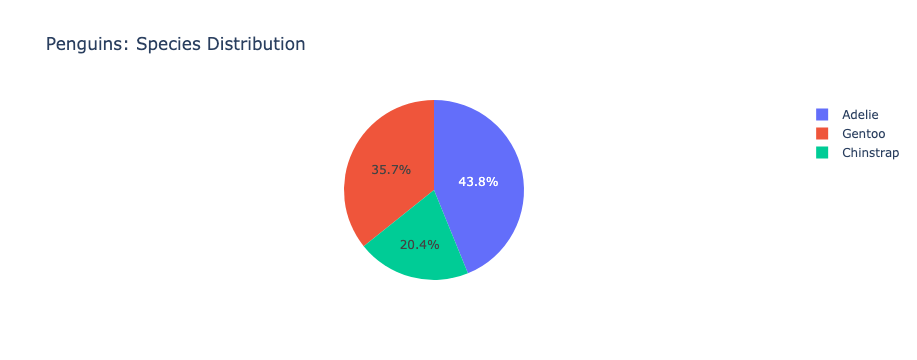

In [177]:
# თითოეული სახეობის რაოდენობა
species_counts = df["species"].value_counts().reset_index()
species_counts.columns = ["species", "count"]

# Pie Chart: რომელი სახეობიდან რამდენი პინგვინი გვხვდება
fig_pie = px.pie(
    species_counts,
    names="species",      # კატეგორიები – პინგვინის სახეობა
    values="count",       # თითოეული კატეგორიის რაოდენობა
    title="Penguins: Species Distribution"
)
fig_pie.show()

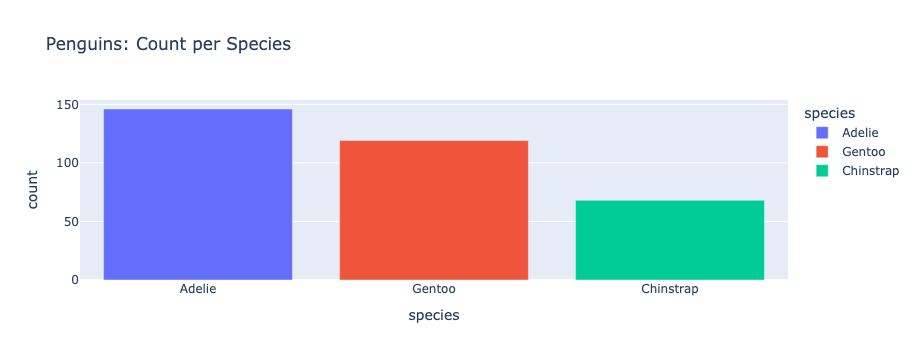

In [182]:
# Bar plot
fig_bar = px.bar(
    species_counts,
    x="species",
    y="count",
    color="species",
    title="Penguins: Count per Species"
)
fig_bar.show()

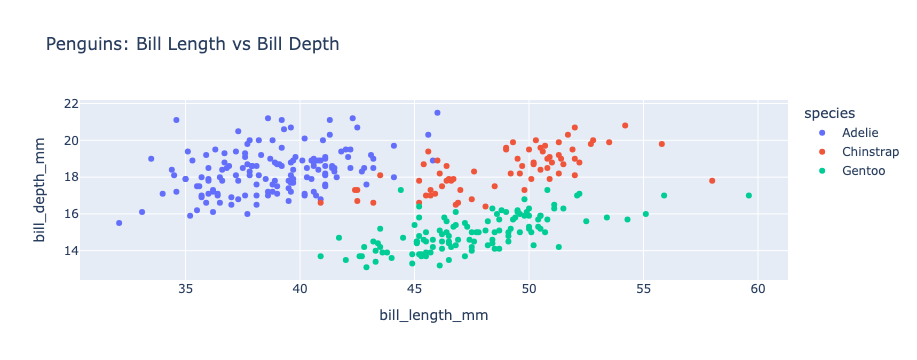

In [185]:
# Scatter Plot: Bill Length vs. Bill Depth, რომელშიც თითოეული პინგვინის სახეობა განსხვავებული ფერითაა ნაჩვენები
fig_scatter = px.scatter(
    df,
    x="bill_length_mm",
    y="bill_depth_mm",
    color="species",
    title="Penguins: Bill Length vs Bill Depth"
)
fig_scatter.show()

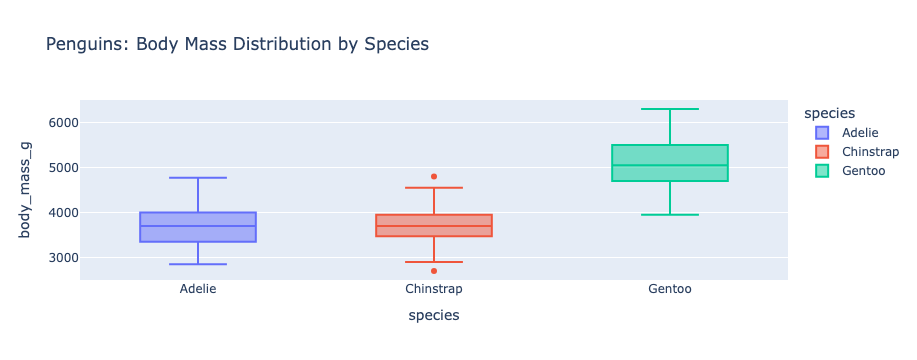

In [188]:
# Box Plot: Body Mass-ის განაწილება სხვადასხვა სახეობის მიხედვით
fig_box = px.box(
    df,
    x="species",
    y="body_mass_g",
    color="species",
    title="Penguins: Body Mass Distribution by Species"
)
fig_box.show()

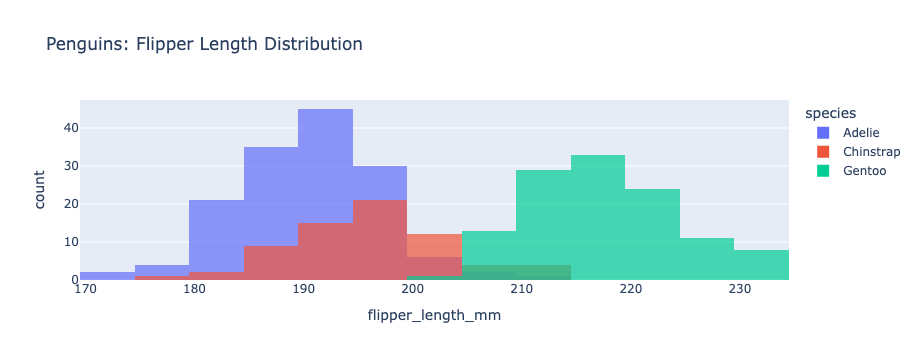

In [191]:
# Histogram: Flipper Length-ის განაწილება, თითოეული სახეობის მიხედვით
fig_hist = px.histogram(
    df,
    x="flipper_length_mm",
    color="species",
    title="Penguins: Flipper Length Distribution",
    barmode="overlay",  # თითოეული კატეგორია "overlay" რეჟიმში არის ნაჩვენები
    opacity=0.7        
)
fig_hist.show()